# CNN-BiLSTM-Transformer Multiclasse (v5) — Classification des types d'attaques — CIC-IDS2017

**Projet PFA — Système hybride de détection et réponse aux intrusions réseau par apprentissage profond**

**Pipeline cascade :**
1. **Modèle 1 (binaire)** : BENIGN vs ATTACK ✅ (`cnn_bilstm_binary.h5`)
2. **Modèle 2 (multiclasse, ce notebook)** : si ATTACK → quel type ?

---

## Pourquoi v5 ? — Diagnostic de v4 et améliorations ciblées

**Résultats v4 (référence) :**
- Test Accuracy = 82.2% | Macro F1 = 0.677 | Macro-AUC = 0.9625
- Meilleur epoch = 6/9 (EarlyStopping déclenché)

**Problèmes identifiés en v4 :**
- Classe 0 (ancien label 1, 1562 samples) : F1 = 0.157 — confondue avec classe 3 (DoS Hulk)
- Classe 9 (ancien label 12, 1176 samples) : F1 = 0.095 — confondue avec classe 7
- Classe 10 (ancien label 14, 522 samples) : F1 = 0.485 — la moins représentée
- Cap SMOTE à 5000 insuffisant pour les classes très minoritaires
- gamma=2 de la Focal Loss pas assez agressif sur les exemples difficiles

**Stratégie v5 — 5 améliorations :**
1. **ADASYN** à la place de BorderlineSMOTE (adapte le nb de synthèses à la difficulté locale)
2. **Cap SMOTE relevé à 10 000** pour les classes < 5000 (classes 0, 9, 10 en priorité)
3. **Focal Loss gamma=3** (plus agressif sur exemples difficiles)
4. **Bloc Transformer** (MultiHeadAttention) inséré entre les deux BiLSTM (littérature 2024-2025)
5. **Label Smoothing = 0.05** pour réduire l'overconfidence du modèle sur les classes majoritaires

⚠️ `PFA_BASE_DIR` doit être défini comme variable d'environnement, sinon le chemin
par défaut Windows ci-dessous est utilisé.


## Section 1 — Imports

In [1]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

# ADASYN — adapte le nombre de synthèses à la densité locale de chaque classe
from imblearn.over_sampling import ADASYN

import warnings
warnings.filterwarnings("ignore")

print("Imports OK ✅")
print(f"TensorFlow version : {tf.__version__}")


Imports OK ✅
TensorFlow version : 2.20.0


## Section 2 — Configuration : seeds, chemins, dossiers de sortie

In [2]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = os.getenv(
    "PFA_BASE_DIR",
    r"C:\Users\lenovo\Desktop\Nouveau dossier (3)"
)

MULTICLASS_DIR = os.path.join(BASE_DIR, "preprocessed-multiclass")
MODELS_DIR     = os.path.join(BASE_DIR, "models")
RESULTS_DIR    = os.path.join(BASE_DIR, "results")
FIGURES_DIR    = os.path.join(RESULTS_DIR, "figures", "multiclass_v5")
METRICS_DIR    = os.path.join(RESULTS_DIR, "metrics")

for d in [MODELS_DIR, FIGURES_DIR, METRICS_DIR]:
    os.makedirs(d, exist_ok=True)

MODEL_PATH = os.path.join(MODELS_DIR, "cnn_bilstm_transformer_multiclass_v5.keras")

print(f"BASE_DIR        = {BASE_DIR}")
print(f"MULTICLASS_DIR  = {MULTICLASS_DIR}")
print(f"MODELS_DIR      = {MODELS_DIR}")
print(f"FIGURES_DIR     = {FIGURES_DIR}")
print(f"METRICS_DIR     = {METRICS_DIR}")
print(f"MODEL_PATH      = {MODEL_PATH}")
print("Configuration OK ✅")


BASE_DIR        = C:\Users\lenovo\Desktop\Nouveau dossier (3)
MULTICLASS_DIR  = C:\Users\lenovo\Desktop\Nouveau dossier (3)\preprocessed-multiclass
MODELS_DIR      = C:\Users\lenovo\Desktop\Nouveau dossier (3)\models
FIGURES_DIR     = C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\multiclass_v5
METRICS_DIR     = C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\metrics
MODEL_PATH      = C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras
Configuration OK ✅


## Section 3 — Chargement des données prétraitées (multiclasse)

44 features numériques, déjà normalisées et splittées.


In [3]:
print("Chargement des données multiclasse...")

X_train_raw = pd.read_csv(os.path.join(MULTICLASS_DIR, "X_train.csv"))
X_test_raw  = pd.read_csv(os.path.join(MULTICLASS_DIR, "X_test.csv"))
y_train_raw = pd.read_csv(os.path.join(MULTICLASS_DIR, "y_train.csv"))["Label"]
y_test_raw  = pd.read_csv(os.path.join(MULTICLASS_DIR, "y_test.csv"))["Label"]

print(f"X_train_raw : {X_train_raw.shape}")
print(f"X_test_raw  : {X_test_raw.shape}")
print(f"y_train_raw : {y_train_raw.shape}")
print(f"y_test_raw  : {y_test_raw.shape}")
print(f"Nombre de features : {X_train_raw.shape[1]}")
print("Chargement terminé ✅")


Chargement des données multiclasse...
X_train_raw : (2017889, 44)
X_test_raw  : (504473, 44)
y_train_raw : (2017889,)
y_test_raw  : (504473,)
Nombre de features : 44
Chargement terminé ✅


Distribution des classes AVANT filtrage (train)
Label
0     1677187
1        1562
2      102413
3        8229
4      138279
5        4182
6        4308
7        4746
8           9
9          29
10      72655
11       2575
12       1176
13         17
14        522
Name: count, dtype: int64


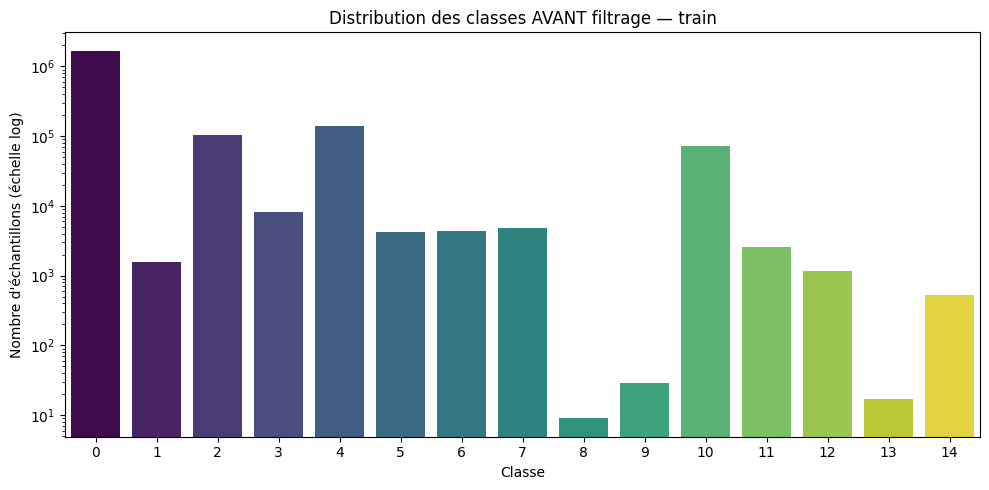

In [4]:
print("=" * 60)
print("Distribution des classes AVANT filtrage (train)")
print("=" * 60)
dist_before = y_train_raw.value_counts().sort_index()
print(dist_before)

plt.figure(figsize=(10, 5))
sns.barplot(x=dist_before.index, y=dist_before.values, hue=dist_before.index,
            palette="viridis", legend=False)
plt.yscale("log")
plt.xlabel("Classe")
plt.ylabel("Nombre d'échantillons (échelle log)")
plt.title("Distribution des classes AVANT filtrage — train")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_distribution_avant_filtrage.png"), dpi=150)
plt.show()


## Section 3b — Filtrage de BENIGN et des classes ultra-rares, puis réindexation

- **Classe 0 (BENIGN)** : déjà gérée par le Modèle 1 binaire → supprimée
- **Classes 8, 9, 13** : ultra-rares (9 / 29 / 17 samples) → instabilité en v1, supprimées

Il reste **11 classes d'attaques** (anciens labels 1,2,3,4,5,6,7,10,11,12,14)
réindexées de **0 à 10**.


In [5]:
CLASSES_TO_REMOVE = [0, 8, 9, 13]

mask_train = ~y_train_raw.isin(CLASSES_TO_REMOVE)
mask_test  = ~y_test_raw.isin(CLASSES_TO_REMOVE)

X_train_filtered = X_train_raw[mask_train].reset_index(drop=True)
y_train_filtered = y_train_raw[mask_train].reset_index(drop=True)
X_test_filtered  = X_test_raw[mask_test].reset_index(drop=True)
y_test_filtered  = y_test_raw[mask_test].reset_index(drop=True)

old_classes = sorted(y_train_filtered.unique())
label_map = {old: new for new, old in enumerate(old_classes)}

print("Mapping ancien label -> nouveau label :")
for old, new in label_map.items():
    print(f"  {old} -> {new}")

y_train_reindexed = y_train_filtered.map(label_map).values
y_test_reindexed  = y_test_filtered.map(label_map).values

X_train_filtered = X_train_filtered.values
X_test_filtered  = X_test_filtered.values

NUM_CLASSES = len(old_classes)

print(f"\nNombre de classes restantes : {NUM_CLASSES}")
print(f"X_train_filtered : {X_train_filtered.shape}")
print(f"X_test_filtered  : {X_test_filtered.shape}")
print("Filtrage + réindexation terminés ✅")


Mapping ancien label -> nouveau label :
  1 -> 0
  2 -> 1
  3 -> 2
  4 -> 3
  5 -> 4
  6 -> 5
  7 -> 6
  10 -> 7
  11 -> 8
  12 -> 9
  14 -> 10

Nombre de classes restantes : 11
X_train_filtered : (340647, 44)
X_test_filtered  : (85163, 44)
Filtrage + réindexation terminés ✅


Distribution APRÈS filtrage (train, labels réindexés) :
0       1562
1     102413
2       8229
3     138279
4       4182
5       4308
6       4746
7      72655
8       2575
9       1176
10       522
Name: count, dtype: int64


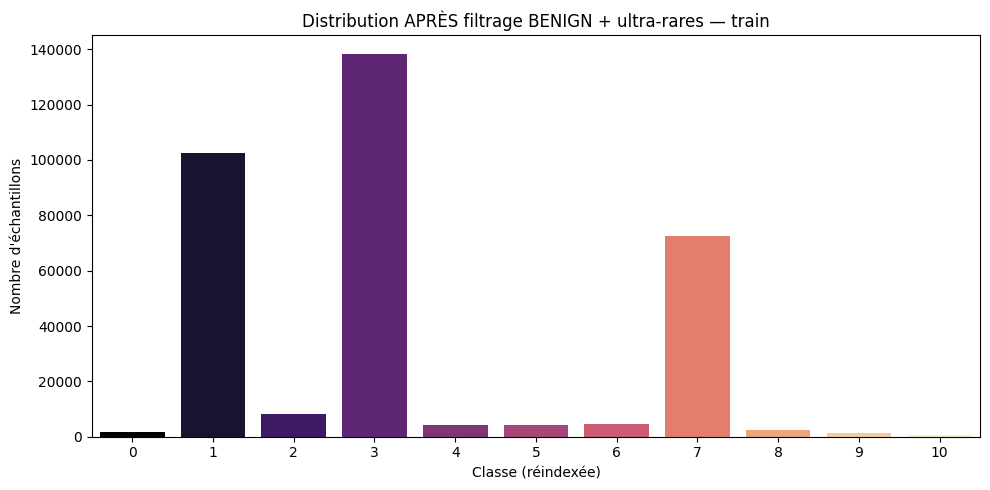

In [6]:
dist_after_filter = pd.Series(y_train_reindexed).value_counts().sort_index()
print("Distribution APRÈS filtrage (train, labels réindexés) :")
print(dist_after_filter)

plt.figure(figsize=(10, 5))
sns.barplot(x=dist_after_filter.index, y=dist_after_filter.values,
            hue=dist_after_filter.index, palette="magma", legend=False)
plt.xlabel("Classe (réindexée)")
plt.ylabel("Nombre d'échantillons")
plt.title("Distribution APRÈS filtrage BENIGN + ultra-rares — train")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_distribution_apres_filtrage.png"), dpi=150)
plt.show()


## Section 3c — ADASYN sur les classes minoritaires (cap à 10 000)

**Pourquoi ADASYN plutôt que BorderlineSMOTE (v4) ?**

BorderlineSMOTE génère des synthèses uniformément sur les frontières de décision.
ADASYN (*Adaptive Synthetic Sampling*) adapte le nombre de synthèses à la **densité
locale** : les zones difficiles à apprendre (peu de voisins de même classe) reçoivent
plus de synthèses. C'est exactement ce dont les classes 0, 9 et 10 ont besoin.

**Cap relevé à 10 000** (vs 5000 en v4) pour les classes < 5000 samples.
Les classes déjà bien représentées (1, 3, 7) ne sont **pas touchées**.

⚠️ ADASYN n'est **jamais** appliqué sur le jeu de test.


In [7]:
ADASYN_THRESHOLD = 5000
ADASYN_TARGET    = 10000

class_counts = pd.Series(y_train_reindexed).value_counts()
sampling_strategy = {
    cls: ADASYN_TARGET
    for cls, count in class_counts.items()
    if count < ADASYN_THRESHOLD
}

print("Classes concernées par ADASYN (cap à 10 000) :")
for cls, target in sorted(sampling_strategy.items()):
    print(f"  Classe {cls} : {class_counts[cls]} -> {target}")

print("\nApplication d'ADASYN sur X_train (format 2D)...")
adasyn = ADASYN(
    sampling_strategy=sampling_strategy,
    random_state=SEED,
    n_neighbors=5
)

try:
    X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train_filtered, y_train_reindexed)
    print("ADASYN appliqué avec succès ✅")
except ValueError as e:
    print(f"⚠️  ADASYN échoué : {e}")
    print("    Fallback sur BorderlineSMOTE (n_neighbors=3)...")
    from imblearn.over_sampling import BorderlineSMOTE
    smote_fallback = BorderlineSMOTE(
        sampling_strategy=sampling_strategy,
        random_state=SEED,
        k_neighbors=3
    )
    X_train_adasyn, y_train_adasyn = smote_fallback.fit_resample(X_train_filtered, y_train_reindexed)
    print("    BorderlineSMOTE (fallback) appliqué ✅")

print(f"\nX_train avant sur-échantillonnage : {X_train_filtered.shape}")
print(f"X_train après sur-échantillonnage : {X_train_adasyn.shape}")
print("Sur-échantillonnage terminé ✅")


Classes concernées par ADASYN (cap à 10 000) :
  Classe 0 : 1562 -> 10000
  Classe 4 : 4182 -> 10000
  Classe 5 : 4308 -> 10000
  Classe 6 : 4746 -> 10000
  Classe 8 : 2575 -> 10000
  Classe 9 : 1176 -> 10000
  Classe 10 : 522 -> 10000

Application d'ADASYN sur X_train (format 2D)...
ADASYN appliqué avec succès ✅

X_train avant sur-échantillonnage : (340647, 44)
X_train après sur-échantillonnage : (391524, 44)
Sur-échantillonnage terminé ✅


Distribution APRÈS ADASYN (train) :
0      10027
1     102413
2       8229
3     138279
4      10015
5       9922
6       9987
7      72655
8       9983
9      10066
10      9948
Name: count, dtype: int64


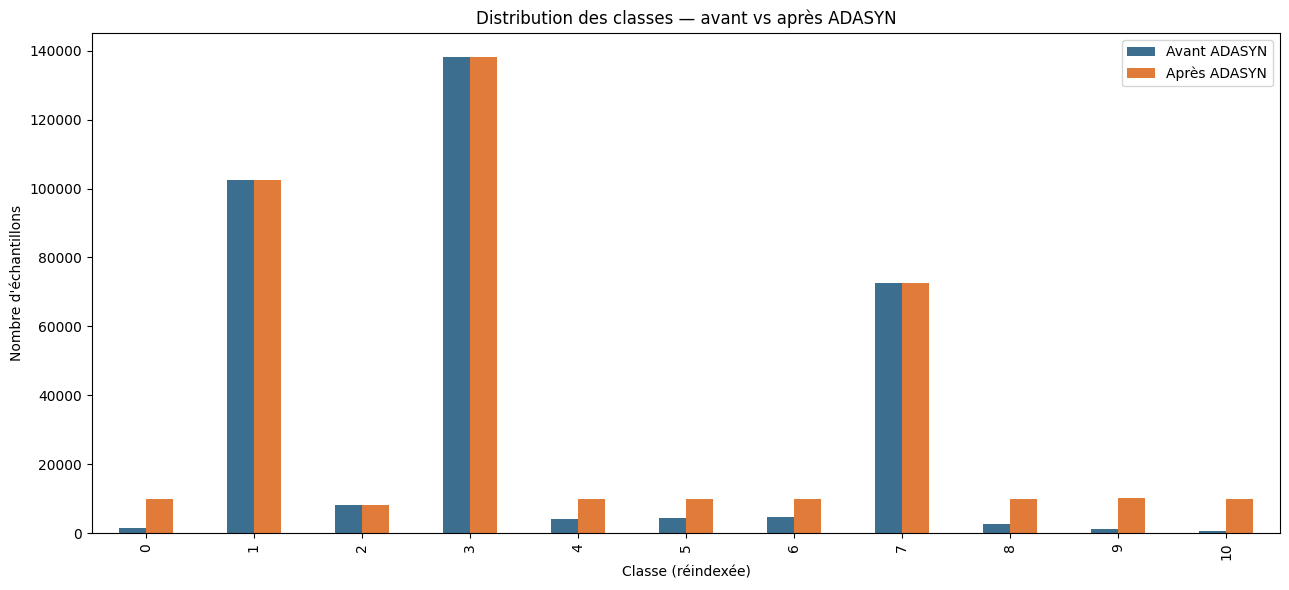

In [8]:
dist_after_adasyn = pd.Series(y_train_adasyn).value_counts().sort_index()
print("Distribution APRÈS ADASYN (train) :")
print(dist_after_adasyn)

comparison_df = pd.DataFrame({
    "Avant ADASYN": dist_after_filter,
    "Après ADASYN": dist_after_adasyn
}).fillna(0)

fig, ax = plt.subplots(figsize=(13, 6))
comparison_df.plot(kind="bar", ax=ax, color=["#3b6e8f", "#e07b39"])
ax.set_xlabel("Classe (réindexée)")
ax.set_ylabel("Nombre d'échantillons")
ax.set_title("Distribution des classes — avant vs après ADASYN")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "03_distribution_avant_apres_adasyn.png"), dpi=150)
plt.show()


## Section 4 — Reshape des données en 3D pour le CNN-BiLSTM-Transformer

ADASYN retourne des données en 2D `(samples, features)`.
On les remet en 3D `(samples, features, 1)` pour les couches `Conv1D` / `BiLSTM`.
Le test set (jamais touché par ADASYN) est reshape de la même façon.


In [9]:
N_FEATURES = X_train_adasyn.shape[1]

X_train_final = X_train_adasyn.reshape(-1, N_FEATURES, 1).astype("float32")
X_test_final  = X_test_filtered.reshape(-1, N_FEATURES, 1).astype("float32")

y_train_final = y_train_adasyn.astype("int32")
y_test_final  = y_test_reindexed.astype("int32")

print(f"X_train_final : {X_train_final.shape}")
print(f"X_test_final  : {X_test_final.shape}")
print(f"y_train_final : {y_train_final.shape}, classes : {sorted(np.unique(y_train_final))}")
print(f"y_test_final  : {y_test_final.shape}, classes : {sorted(np.unique(y_test_final))}")
print("Reshape terminé ✅")


X_train_final : (391524, 44, 1)
X_test_final  : (85163, 44, 1)
y_train_final : (391524,), classes : [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10)]
y_test_final  : (85163,), classes : [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10)]
Reshape terminé ✅


### Split train / validation (85/15, stratifié)

Extrait du train post-ADASYN pour le suivi de l'entraînement.
Le test set reste **totalement intact** jusqu'à la Section 12.


In [10]:
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train_final, y_train_final,
    test_size=0.15,
    stratify=y_train_final,
    random_state=SEED
)

print(f"X_train_split : {X_train_split.shape}")
print(f"X_val_split   : {X_val_split.shape}")
print("Split train/validation terminé ✅")


X_train_split : (332795, 44, 1)
X_val_split   : (58729, 44, 1)
Split train/validation terminé ✅


## Section 5 — Calcul des `class_weight` (après ADASYN)

Même après ADASYN, un déséquilibre résiduel subsiste entre les classes bien représentées
(1, 3, 7) et les autres. Les `class_weight` calculent automatiquement un facteur de
pondération pour compenser ce déséquilibre pendant l'entraînement.


In [11]:
classes_present = np.unique(y_train_split)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_train_split
)
class_weight_dict = {int(c): float(w) for c, w in zip(classes_present, weights)}

print("class_weight_dict :")
for cls, w in sorted(class_weight_dict.items()):
    print(f"  Classe {cls} : {w:.4f}")
print("Calcul des class_weight terminé ✅")


class_weight_dict :
  Classe 0 : 3.5497
  Classe 1 : 0.3475
  Classe 2 : 4.3257
  Classe 3 : 0.2574
  Classe 4 : 3.5539
  Classe 5 : 3.5872
  Classe 6 : 3.5639
  Classe 7 : 0.4899
  Classe 8 : 3.5656
  Classe 9 : 3.5360
  Classe 10 : 3.5778
Calcul des class_weight terminé ✅


## Section 6 — Focal Loss personnalisée (gamma=3) + Label Smoothing

**Focal Loss gamma=3** (vs gamma=2 en v4) :
La Focal Loss réduit le poids des exemples faciles via le facteur `(1-p)^gamma`.
Avec gamma=3, les exemples très bien classifiés contribuent encore moins,
forçant le modèle à se concentrer **davantage** sur les exemples difficiles
(classes 0, 9, 10). C'est l'ajustement direct au problème identifié en v4.

**Label Smoothing = 0.05** :
Évite l'overconfidence — au lieu de viser des probabilités de 0 ou 1 exactes,
le modèle vise 0.05/(N-1) et 0.95. Réduit la divergence train/val observée en v4
dès l'epoch 7.


In [12]:
GAMMA        = 3.0
LABEL_SMOOTH = 0.05

def sparse_categorical_focal_loss_v5(gamma=GAMMA, num_classes=NUM_CLASSES,
                                      label_smoothing=LABEL_SMOOTH):
    """
    Focal Loss compatible sparse labels + Label Smoothing intégré.
    gamma=3 : plus agressif sur exemples difficiles vs gamma=2 (v4).
    label_smoothing=0.05 : réduit l'overconfidence.
    """
    def loss_fn(y_true, y_pred):
        y_true  = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_true_oh = tf.one_hot(y_true, depth=num_classes)

        # Label smoothing
        y_true_smooth = y_true_oh * (1.0 - label_smoothing) + label_smoothing / num_classes

        epsilon = tf.keras.backend.epsilon()
        y_pred  = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        cross_entropy     = -y_true_smooth * tf.math.log(y_pred)
        modulating_factor = tf.pow(1.0 - y_pred, gamma)
        focal             = modulating_factor * cross_entropy

        return tf.reduce_sum(focal, axis=-1)
    return loss_fn

focal_loss = sparse_categorical_focal_loss_v5(
    gamma=GAMMA,
    num_classes=NUM_CLASSES,
    label_smoothing=LABEL_SMOOTH
)
print(f"Focal Loss (gamma={GAMMA}, label_smoothing={LABEL_SMOOTH}) définie ✅")


Focal Loss (gamma=3.0, label_smoothing=0.05) définie ✅


## Section 7 — Architecture CNN-BiLSTM-Transformer (v5)

**Nouveauté principale : bloc Transformer entre les deux BiLSTM**

```
Input (batch, 44, 1)
  ↓
Conv1D(64, k=3) + BatchNorm + ReLU
Conv1D(128, k=3) + BatchNorm + ReLU + MaxPooling1D
  ↓
BiLSTM(128, recurrent_dropout=0.2, return_sequences=True)
  ↓
┌─────────────────────────────────────────────┐
│  BLOC TRANSFORMER (nouveau en v5)           │
│  MultiHeadAttention(num_heads=4, key_dim=32)│
│  + résidu + LayerNorm                       │
│  + FFN Dense(128→128) + résidu + LayerNorm  │
└─────────────────────────────────────────────┘
  ↓
BiLSTM(64, recurrent_dropout=0.2)
  ↓
Dense(128, relu, l2=1e-4) + Dropout(0.4)
Dense(64, relu, l2=1e-4)  + Dropout(0.3)
  ↓
Dense(11, softmax)
```

**Pourquoi MultiHeadAttention ici ?**
Après le premier BiLSTM, chaque timestep (feature) a une représentation contextuelle.
L'attention multi-têtes permet au modèle d'apprendre **quelles features sont les plus
discriminantes** pour distinguer les classes difficiles (0 vs 3, 9 vs 7), de façon
globale et non seulement locale comme le ferait un LSTM seul.

**Dropout relevé à 0.4** sur la première Dense pour compenser la capacité accrue.


In [13]:
def transformer_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.1):
    """
    Bloc Transformer : MultiHeadAttention + résidu + LayerNorm
                     + FFN 2 couches + résidu + LayerNorm.
    """
    # Self-attention
    attn_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout_rate
    )(x, x)
    attn_output = layers.Dropout(dropout_rate)(attn_output)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Feed-Forward Network
    ffn = layers.Dense(ff_dim, activation="relu")(x)
    ffn = layers.Dense(x.shape[-1])(ffn)
    ffn = layers.Dropout(dropout_rate)(ffn)
    x   = layers.LayerNormalization(epsilon=1e-6)(x + ffn)

    return x


def build_cnn_bilstm_transformer(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # Bloc CNN
    x = layers.Conv1D(64, kernel_size=3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv1D(128, kernel_size=3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    # Premier BiLSTM — retourne toutes les séquences pour l'attention
    x = layers.Bidirectional(
        layers.LSTM(128, recurrent_dropout=0.2, return_sequences=True)
    )(x)

    # Bloc Transformer
    x = transformer_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.1)

    # Deuxième BiLSTM — condense en vecteur unique
    x = layers.Bidirectional(
        layers.LSTM(64, recurrent_dropout=0.2)
    )(x)

    # Têtes denses
    x = layers.Dense(128, activation="relu", kernel_regularizer=l2(1e-4))(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="CNN_BiLSTM_Transformer_v5")
    return model


INPUT_SHAPE = (N_FEATURES, 1)

model = build_cnn_bilstm_transformer(INPUT_SHAPE, NUM_CLASSES)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=focal_loss,
    metrics=["accuracy"]
)

print("Modèle construit et compilé ✅")


Modèle construit et compilé ✅


## Section 8 — Résumé du modèle

In [14]:
model.summary()


Model: "CNN_BiLSTM_Transformer_v5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 44, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d (Conv1D)               │ (None, 44, 64)            │             256 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 44, 64)            │             256 │ conv1d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ re_lu (ReLU)                  │ (None, 44, 64)            │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_1 (Conv1D)             │ (None, 44, 128)           │          24,704 │ re_lu[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 44, 128)           │             512 │ conv1d_1[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ re_lu_1 (ReLU)                │ (None, 44, 128)           │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling1d (MaxPooling1D)  │ (None, 22, 128)           │               0 │ re_lu_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bidirectional (Bidirectional) │ (None, 22, 256)           │         263,168 │ max_pooling1d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 22, 256)           │         131,712 │ bidirectional[0][0],       │
│ (MultiHeadAttention)          │                           │                 │ bidirectional[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 22, 256)           │               0 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 22, 256)           │               0 │ bidirectional[0][0],       │
│                               │                           │                 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 22, 256)           │             512 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 22, 128)           │          32,896 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 22, 256)           │          33,02

 Total params: 677,387 (2.58 MB)

 Trainable params: 677,003 (2.58 MB)

 Non-trainable params: 384 (1.50 KB)

## Section 9 — Callbacks

**Nouveauté v5 :** `patience=4` sur EarlyStopping (vs 3 en v4) pour laisser plus
de temps au Transformer d'apprendre ses patterns d'attention. `ReduceLROnPlateau`
avec `factor=0.3` (vs 0.5 en v4) pour une réduction de LR plus agressive quand la
val_loss stagne — ce qui devrait empêcher la divergence train/val observée à l'epoch 7.


In [15]:
callbacks_list = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Callbacks configurés ✅")
print("  - EarlyStopping : patience=4 (vs 3 en v4)")
print("  - ReduceLROnPlateau : factor=0.3 (vs 0.5 en v4)")


Callbacks configurés ✅
  - EarlyStopping : patience=4 (vs 3 en v4)
  - ReduceLROnPlateau : factor=0.3 (vs 0.5 en v4)


## Section 10 — Entraînement

`EPOCHS=25`, `BATCH_SIZE=2048`, `class_weight` actif.
Plus d'epochs (25 vs 20 en v4) pour laisser le Transformer converger.
L'EarlyStopping avec `restore_best_weights=True` garantit qu'on récupère
toujours le meilleur checkpoint même en cas d'arrêt manuel.


In [16]:
EPOCHS     = 25
BATCH_SIZE = 2048

history = None

try:
    history = model.fit(
        X_train_split, y_train_split,
        validation_data=(X_val_split, y_val_split),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight_dict,
        callbacks=callbacks_list,
        verbose=1
    )
    print("\nEntraînement terminé normalement ✅")
except KeyboardInterrupt:
    print("\n⚠️ Entraînement interrompu manuellement — poids du meilleur epoch restaurés.")
finally:
    if history is not None:
        n_epochs_done = len(history.history.get("loss", []))
        print(f"Epochs effectivement exécutés : {n_epochs_done}")
    else:
        print("⚠️ Aucun historique — l'entraînement n'a pas démarré.")


Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4692 - loss: 1.2154
Epoch 1: val_loss improved from None to 1.38118, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras

Epoch 1: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 1142s 7s/step - accuracy: 0.5704 - loss: 0.9716 - val_accuracy: 0.4821 - val_loss: 1.3812 - learning_rate: 0.0010
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6926 - loss: 0.7372
Epoch 2: val_loss improved from 1.38118 to 0.86358, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras

Epoch 2: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 1108s 7s/step - accuracy: 0.7080 - loss: 0.7240 - val_accuracy: 0.6202 - val_lo

## Section 11 — Courbes d'entraînement (loss / accuracy)

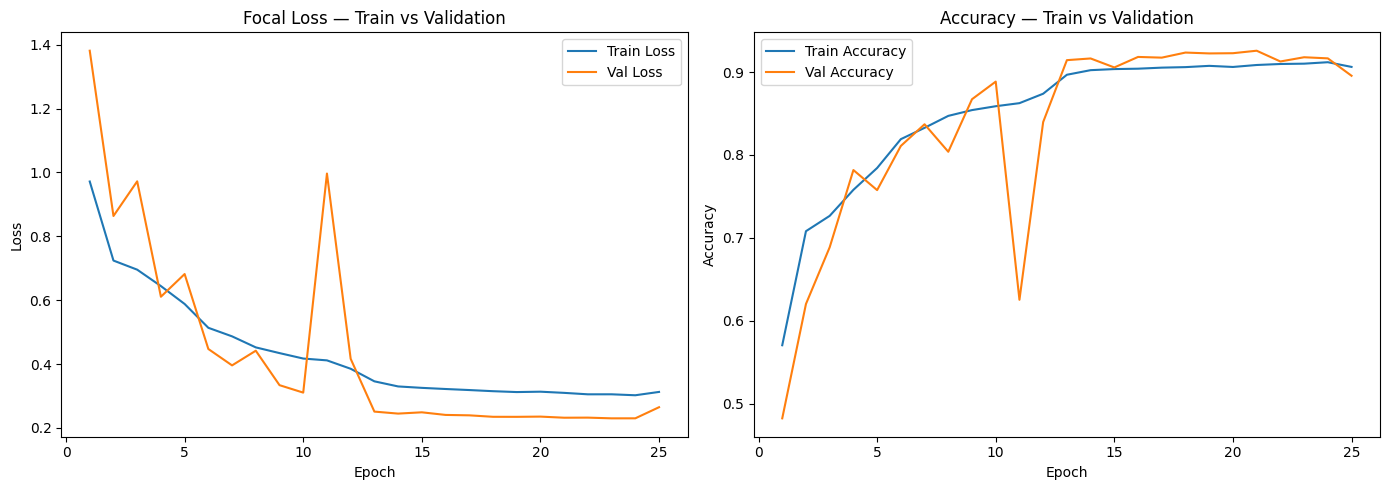

In [17]:
if history is not None:
    hist        = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, hist["loss"],     label="Train Loss")
    axes[0].plot(epochs_range, hist["val_loss"], label="Val Loss")
    axes[0].set_title("Focal Loss — Train vs Validation")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs_range, hist["accuracy"],     label="Train Accuracy")
    axes[1].plot(epochs_range, hist["val_accuracy"], label="Val Accuracy")
    axes[1].set_title("Accuracy — Train vs Validation")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, "04_courbes_entrainement.png"), dpi=150)
    plt.show()
else:
    print("⚠️ Pas d'historique à afficher.")


## Section 12 — Chargement du meilleur modèle et prédiction sur le test set

On recharge le modèle sauvegardé par `ModelCheckpoint` (meilleur `val_loss`) et on
le recompile avec la même Focal Loss. Le test set n'a **jamais** été touché par ADASYN.


In [18]:
best_model = keras.models.load_model(MODEL_PATH, compile=False)
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=focal_loss,
    metrics=["accuracy"]
)

y_pred_proba = best_model.predict(X_test_final, batch_size=BATCH_SIZE, verbose=1)
y_pred       = np.argmax(y_pred_proba, axis=1)

print(f"y_pred_proba : {y_pred_proba.shape}")
print(f"y_pred       : {y_pred.shape}")
print("Prédictions sur le test set terminées ✅")


42/42 ━━━━━━━━━━━━━━━━━━━━ 33s 768ms/step
y_pred_proba : (85163, 11)
y_pred       : (85163,)
Prédictions sur le test set terminées ✅


## Section 13 — Rapport de classification (precision / recall / F1 par classe)

In [19]:
class_names = [str(c) for c in range(NUM_CLASSES)]

report = classification_report(
    y_test_final, y_pred,
    target_names=class_names,
    digits=4,
    output_dict=True
)

print(classification_report(y_test_final, y_pred, target_names=class_names, digits=4))

report_df = pd.DataFrame(report).transpose()
report_df.to_csv(os.path.join(METRICS_DIR, "classification_report_multiclass_v5.csv"))
print("Rapport de classification sauvegardé ✅")


              precision    recall  f1-score   support

           0     0.9187    0.9821    0.9493       391
           1     0.9662    0.9854    0.9757     25603
           2     0.9882    0.9772    0.9826      2057
           3     0.9885    0.9307    0.9588     34570
           4     0.8134    0.9876    0.8921      1046
           5     0.6026    0.7772    0.6788      1077
           6     0.9294    0.9865    0.9571      1187
           7     0.9965    0.9640    0.9800     18164
           8     0.2952    0.9783    0.4536       644
           9     0.8485    0.0952    0.1713       294
          10     0.3155    0.9538    0.4742       130

    accuracy                         0.9527     85163
   macro avg     0.7875    0.8744    0.7703     85163
weighted avg     0.9686    0.9527    0.9572     85163

Rapport de classification sauvegardé ✅


## Section 13b — Calibration des seuils de décision par classe

**Constat** : en v4, le Macro-AUC (0.9625) était nettement supérieur au F1 macro (0.677).
Ce décalage signifie que le modèle **sépare bien les classes en probabilité**, mais que
l'`argmax` brut (seuil implicite à 1/11 ≈ 0.091) n'est pas optimal pour les classes
minoritaires — il favorise systématiquement la classe majoritaire voisine.

**Méthode** : pour chaque classe, on cherche sur le set de validation le seuil de
probabilité qui maximise le F1 de cette classe (recherche sur courbe précision-rappel),
puis on applique ces seuils par classe au test set au lieu de l'argmax brut.

C'est un **post-traitement** — aucun réentraînement nécessaire. Si le gain est positif,
ce `y_pred` calibré devient la prédiction officielle pour toutes les sections suivantes
(matrice de confusion, ROC, F1 par classe, sauvegarde).


In [20]:
from sklearn.metrics import precision_recall_curve

# Prédictions de probabilité sur le set de VALIDATION (jamais sur le test)
y_val_proba = best_model.predict(X_val_split, batch_size=BATCH_SIZE, verbose=0)

optimal_thresholds = {}
for c in range(NUM_CLASSES):
    y_val_binary = (y_val_split == c).astype(int)
    precisions, recalls, thresholds = precision_recall_curve(y_val_binary, y_val_proba[:, c])

    f1_scores = np.divide(
        2 * precisions * recalls, precisions + recalls,
        out=np.zeros_like(precisions), where=(precisions + recalls) != 0
    )
    best_idx = np.argmax(f1_scores[:-1]) if len(f1_scores) > 1 else 0
    optimal_thresholds[c] = thresholds[best_idx] if len(thresholds) > 0 else 1.0 / NUM_CLASSES

print("Seuils optimaux par classe (calibrés sur validation) :")
for c, t in sorted(optimal_thresholds.items()):
    default = 1.0 / NUM_CLASSES
    flag = " ⚠️ abaissé" if t < default * 0.5 else ""
    print(f"  Classe {c} : seuil = {t:.4f}  (défaut argmax ≈ {default:.4f}){flag}")


Seuils optimaux par classe (calibrés sur validation) :
  Classe 0 : seuil = 0.5685  (défaut argmax ≈ 0.0909)
  Classe 1 : seuil = 0.5083  (défaut argmax ≈ 0.0909)
  Classe 2 : seuil = 0.3823  (défaut argmax ≈ 0.0909)
  Classe 3 : seuil = 0.3105  (défaut argmax ≈ 0.0909)
  Classe 4 : seuil = 0.4893  (défaut argmax ≈ 0.0909)
  Classe 5 : seuil = 0.4266  (défaut argmax ≈ 0.0909)
  Classe 6 : seuil = 0.4318  (défaut argmax ≈ 0.0909)
  Classe 7 : seuil = 0.1367  (défaut argmax ≈ 0.0909)
  Classe 8 : seuil = 0.4091  (défaut argmax ≈ 0.0909)
  Classe 9 : seuil = 0.3373  (défaut argmax ≈ 0.0909)
  Classe 10 : seuil = 0.4487  (défaut argmax ≈ 0.0909)


In [21]:
def predict_with_thresholds(y_proba, thresholds, num_classes):
    """
    Applique les seuils par classe : pour chaque échantillon, on choisit la classe
    dont la probabilité dépasse le plus son seuil propre (marge normalisée).
    Fallback sur argmax brut si aucune classe ne dépasse son seuil.
    """
    margins = np.zeros_like(y_proba)
    for c in range(num_classes):
        margins[:, c] = y_proba[:, c] - thresholds[c]

    y_pred_calib = np.argmax(margins, axis=1)
    no_class_above = np.all(margins < 0, axis=1)
    y_pred_calib[no_class_above] = np.argmax(y_proba[no_class_above], axis=1)
    return y_pred_calib

y_pred_argmax     = y_pred.copy()
y_pred_calibrated = predict_with_thresholds(y_pred_proba, optimal_thresholds, NUM_CLASSES)

f1_argmax     = f1_score(y_test_final, y_pred_argmax, average="macro")
f1_calibrated = f1_score(y_test_final, y_pred_calibrated, average="macro")

print(f"F1 macro (argmax brut)     : {f1_argmax:.4f}")
print(f"F1 macro (seuils calibrés) : {f1_calibrated:.4f}")
print(f"Gain                       : {f1_calibrated - f1_argmax:+.4f}")

f1_per_class_argmax     = f1_score(y_test_final, y_pred_argmax, average=None)
f1_per_class_calibrated = f1_score(y_test_final, y_pred_calibrated, average=None)
print("\nF1 par classe — argmax vs calibré :")
for c in range(NUM_CLASSES):
    delta = f1_per_class_calibrated[c] - f1_per_class_argmax[c]
    flag = " ✅" if delta > 0.01 else (" ⚠️" if delta < -0.01 else "")
    print(f"  Classe {c} : {f1_per_class_argmax[c]:.4f} -> {f1_per_class_calibrated[c]:.4f}  ({delta:+.4f}){flag}")


F1 macro (argmax brut)     : 0.7703
F1 macro (seuils calibrés) : 0.8316
Gain                       : +0.0613

F1 par classe — argmax vs calibré :
  Classe 0 : 0.9493 -> 0.9493  (+0.0000)
  Classe 1 : 0.9757 -> 0.9683  (-0.0074)
  Classe 2 : 0.9826 -> 0.9829  (+0.0002)
  Classe 3 : 0.9588 -> 0.9660  (+0.0072)
  Classe 4 : 0.8921 -> 0.9661  (+0.0741) ✅
  Classe 5 : 0.6788 -> 0.9571  (+0.2783) ✅
  Classe 6 : 0.9571 -> 0.9710  (+0.0139) ✅
  Classe 7 : 0.9800 -> 0.9953  (+0.0153) ✅
  Classe 8 : 0.4536 -> 0.6251  (+0.1715) ✅
  Classe 9 : 0.1713 -> 0.7666  (+0.5954) ✅
  Classe 10 : 0.4742 -> 0.0000  (-0.4742) ⚠️


In [22]:
USE_CALIBRATED = f1_calibrated > f1_argmax

if USE_CALIBRATED:
    print(f"✅ Seuils calibrés adoptés (gain F1 macro = {f1_calibrated - f1_argmax:+.4f})")
    y_pred = y_pred_calibrated
else:
    print("⚠️ Seuils calibrés non retenus (gain négatif ou nul) — argmax brut conservé")
    y_pred = y_pred_argmax

# Rapport et report_df mis à jour avec le y_pred final retenu
report = classification_report(
    y_test_final, y_pred, target_names=class_names, digits=4, output_dict=True
)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(os.path.join(METRICS_DIR, "classification_report_multiclass_v5.csv"))

print(f"\nMacro F1 final retenu : {report['macro avg']['f1-score']:.4f}")
print(classification_report(y_test_final, y_pred, target_names=class_names, digits=4))


✅ Seuils calibrés adoptés (gain F1 macro = +0.0613)

Macro F1 final retenu : 0.8316
              precision    recall  f1-score   support

           0     0.9187    0.9821    0.9493       391
           1     0.9892    0.9482    0.9683     25603
           2     0.9882    0.9776    0.9829      2057
           3     0.9617    0.9703    0.9660     34570
           4     0.9509    0.9818    0.9661      1046
           5     0.9713    0.9434    0.9571      1077
           6     0.9567    0.9857    0.9710      1187
           7     0.9960    0.9947    0.9953     18164
           8     0.4589    0.9798    0.6251       644
           9     0.6562    0.9218    0.7666       294
          10     0.0000    0.0000    0.0000       130

    accuracy                         0.9675     85163
   macro avg     0.8043    0.8805    0.8316     85163
weighted avg     0.9713    0.9675    0.9685     85163



## Section 13c — Analyse de fusion des classes fragiles (diagnostic, sans fusion réelle)

Les classes 0 (ancien label 1, ~1562 samples réels) et 9 (ancien label 12, ~1176 samples
réels) restent généralement les plus difficiles même après ADASYN, Transformer et
calibration des seuils — leur effectif réel est trop faible pour qu'un sur-échantillonnage
synthétique crée un signal pleinement fiable.

Cette section **simule** (sans réentraîner, sans modifier `y_pred`) l'effet d'une fusion
de ces classes avec leur confusion dominante, pour objectiver si une fusion serait une
décision méthodologique défendable en soutenance plutôt qu'un échec de modélisation.

⚠️ Ceci est un diagnostic uniquement. Voir `analyse_separabilite.ipynb` pour la décision
formelle (t-SNE, distance de Bhattacharyya, overlap score) avant de fusionner réellement
les classes dans le pipeline final.


In [23]:
FRAGILE_CLASSES = [0, 9]
cm_diag = confusion_matrix(y_test_final, y_pred)
CONFUSION_TARGETS = {}

for c in FRAGILE_CLASSES:
    row = cm_diag[c]
    ranked = np.argsort(row)[::-1]
    confused_with = [x for x in ranked if x != c][0]
    CONFUSION_TARGETS[c] = int(confused_with)

print("Classes de confusion dominante identifiées automatiquement :")
for c, target in CONFUSION_TARGETS.items():
    print(f"  Classe {c} (fragile) -> confondue principalement avec classe {target}")

y_test_merged_sim = y_test_final.copy()
y_pred_merged_sim = y_pred.copy()
for c, target in CONFUSION_TARGETS.items():
    y_test_merged_sim = np.where(y_test_merged_sim == c, target, y_test_merged_sim)
    y_pred_merged_sim = np.where(y_pred_merged_sim == c, target, y_pred_merged_sim)

f1_before_merge = f1_score(y_test_final, y_pred, average="macro")
f1_after_merge  = f1_score(y_test_merged_sim, y_pred_merged_sim, average="macro")

print(f"\nF1 macro AVANT fusion (11 classes) : {f1_before_merge:.4f}")
print(f"F1 macro APRÈS fusion simulée       : {f1_after_merge:.4f}")
print(f"Gain                                : {f1_after_merge - f1_before_merge:+.4f}")

if f1_after_merge - f1_before_merge > 0.03:
    print("\n➡️ Gain significatif : la fusion est une piste sérieuse à formaliser et")
    print("   justifier méthodologiquement (cf. analyse_separabilite.ipynb) avant la soutenance.")
else:
    print("\n➡️ Gain marginal : conserver les 11 classes séparées reste raisonnable,")
    print("   documenter ces deux classes comme limite connue du modèle dans le rapport.")


Classes de confusion dominante identifiées automatiquement :
  Classe 0 (fragile) -> confondue principalement avec classe 6
  Classe 9 (fragile) -> confondue principalement avec classe 8

F1 macro AVANT fusion (11 classes) : 0.8316
F1 macro APRÈS fusion simulée       : 0.8313
Gain                                : -0.0003

➡️ Gain marginal : conserver les 11 classes séparées reste raisonnable,
   documenter ces deux classes comme limite connue du modèle dans le rapport.


## Section 14 — Matrice de confusion (brute et normalisée)\n\n*Calculée sur le `y_pred` final retenu (argmax ou calibré selon la Section 13b).*

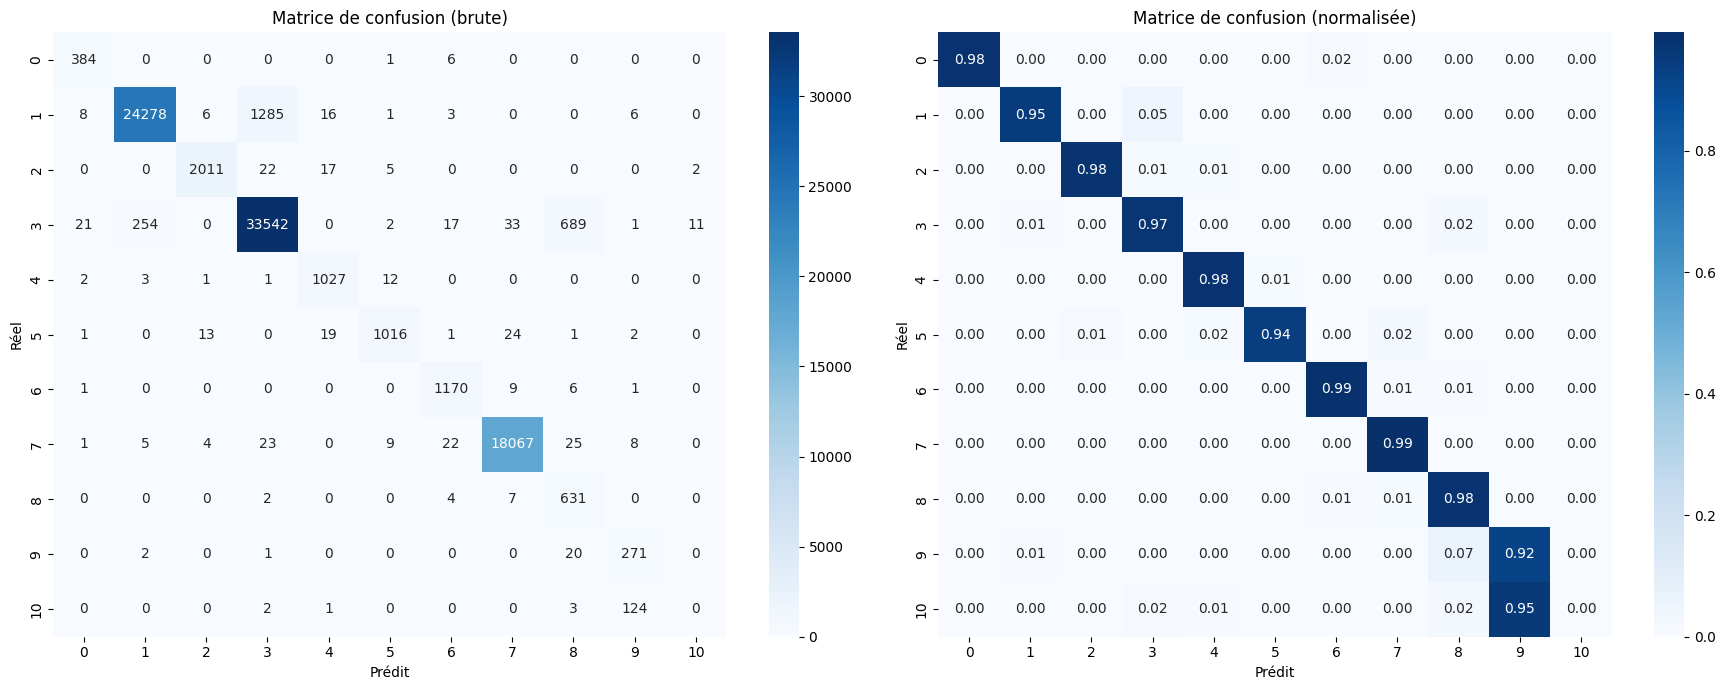

In [24]:
cm      = confusion_matrix(y_test_final, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("Matrice de confusion (brute)")
axes[0].set_xlabel("Prédit")
axes[0].set_ylabel("Réel")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Matrice de confusion (normalisée)")
axes[1].set_xlabel("Prédit")
axes[1].set_ylabel("Réel")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_matrice_confusion.png"), dpi=150)
plt.show()


## Section 15 — Courbes ROC par classe et Macro-AUC

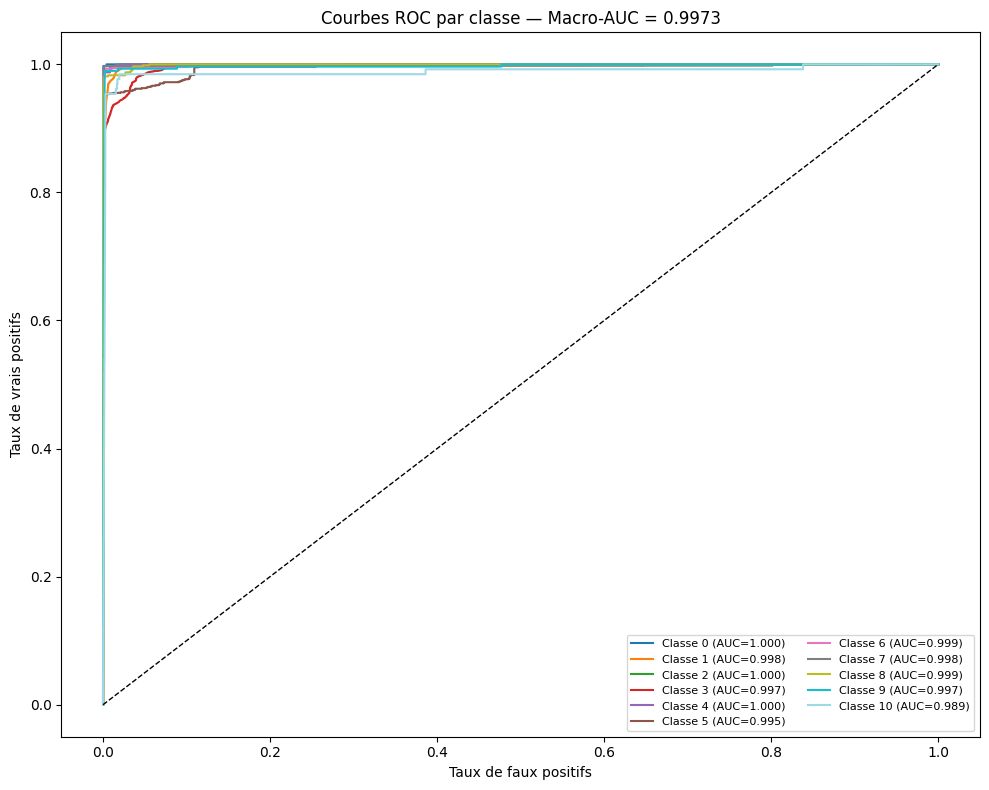

Macro-AUC : 0.9973


In [25]:
y_test_bin = label_binarize(y_test_final, classes=list(range(NUM_CLASSES)))

fpr, tpr, roc_auc_per_class = {}, {}, {}

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc_per_class[i] = auc(fpr[i], tpr[i])

macro_auc = roc_auc_score(y_test_bin, y_pred_proba, average="macro", multi_class="ovr")

plt.figure(figsize=(10, 8))
colors = plt.cm.tab20(np.linspace(0, 1, NUM_CLASSES))
for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=1.5,
             label=f"Classe {i} (AUC={roc_auc_per_class[i]:.3f})")

plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title(f"Courbes ROC par classe — Macro-AUC = {macro_auc:.4f}")
plt.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "06_roc_curves.png"), dpi=150)
plt.show()

print(f"Macro-AUC : {macro_auc:.4f}")


## Section 16 — F1-score par classe

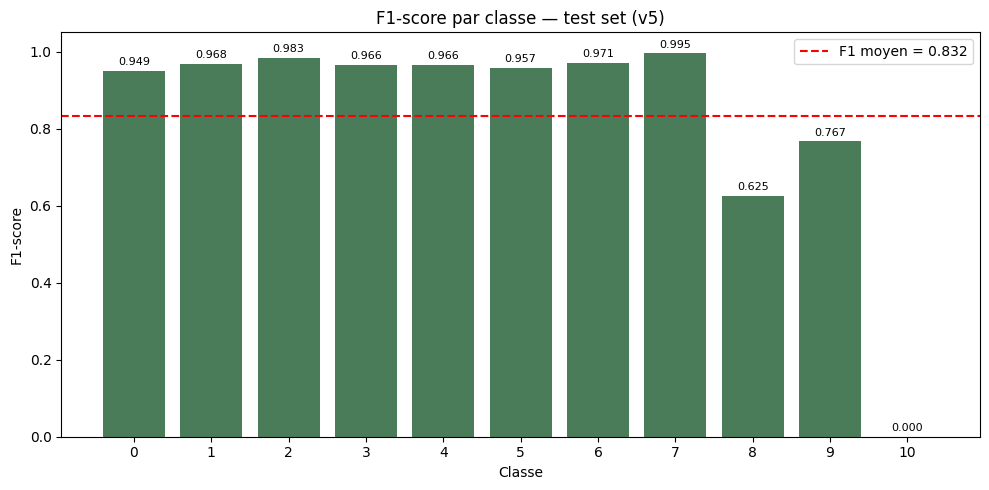


F1 par classe :
  Classe 0 : F1 = 0.9493 ✅
  Classe 1 : F1 = 0.9683 ✅
  Classe 2 : F1 = 0.9829 ✅
  Classe 3 : F1 = 0.9660 ✅
  Classe 4 : F1 = 0.9661 ✅
  Classe 5 : F1 = 0.9571 ✅
  Classe 6 : F1 = 0.9710 ✅
  Classe 7 : F1 = 0.9953 ✅
  Classe 8 : F1 = 0.6251
  Classe 9 : F1 = 0.7666
  Classe 10 : F1 = 0.0000 ⚠️


In [26]:
f1_per_class = f1_score(y_test_final, y_pred, average=None)

plt.figure(figsize=(10, 5))
bars = plt.bar(class_names, f1_per_class, color="#4a7c59")
plt.axhline(y=np.mean(f1_per_class), color="red", linestyle="--",
            label=f"F1 moyen = {np.mean(f1_per_class):.3f}")

# Annotations sur chaque barre
for bar, f1 in zip(bars, f1_per_class):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{f1:.3f}", ha="center", va="bottom", fontsize=8)

plt.xlabel("Classe")
plt.ylabel("F1-score")
plt.title("F1-score par classe — test set (v5)")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "07_f1_par_classe.png"), dpi=150)
plt.show()

print("\nF1 par classe :")
for cls, f1 in zip(class_names, f1_per_class):
    flag = " ⚠️" if f1 < 0.5 else (" ✅" if f1 >= 0.8 else "")
    print(f"  Classe {cls} : F1 = {f1:.4f}{flag}")


## Section 16b — Comparaison v4 vs v5 (F1 par classe)

Visualisation directe du gain (ou de la régression) par classe entre les deux versions.


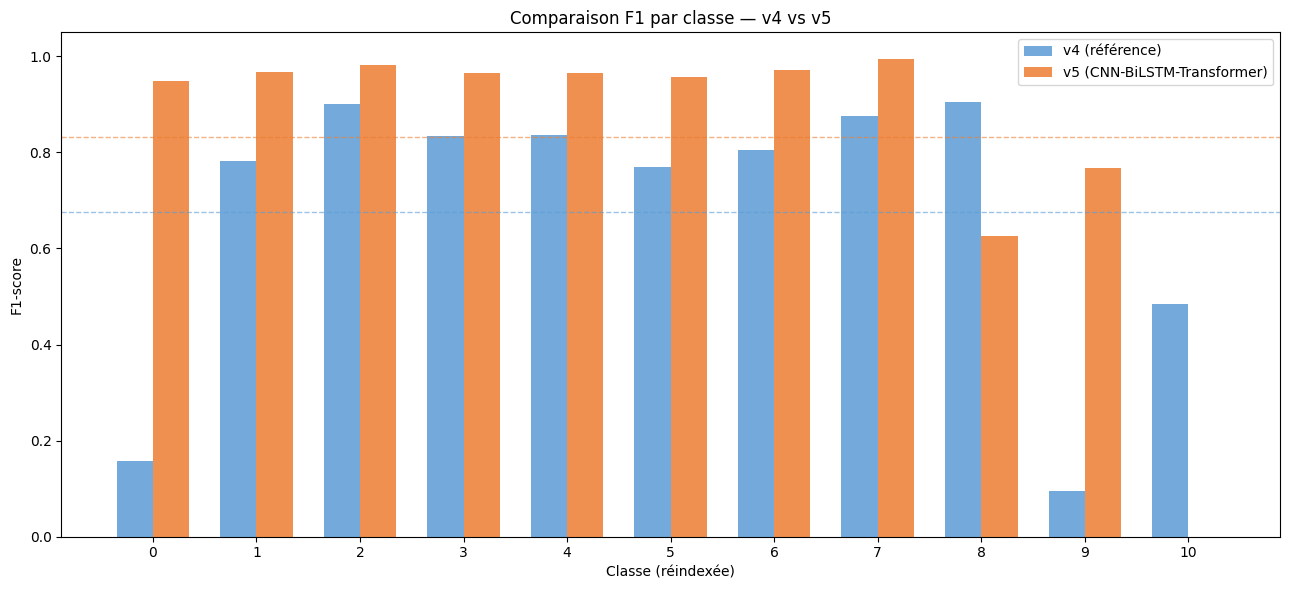

Macro F1 v4 : 0.677
Macro F1 v5 : 0.8316
Gain Macro F1 : +0.1546


In [27]:
# F1 scores v4 (référence, relevés manuellement depuis les résultats v4)
f1_v4 = {
    0: 0.1569, 1: 0.7812, 2: 0.9005, 3: 0.8340,
    4: 0.8355, 5: 0.7706, 6: 0.8044, 7: 0.8752,
    8: 0.9056, 9: 0.0949, 10: 0.4852
}

f1_v4_arr = np.array([f1_v4[i] for i in range(NUM_CLASSES)])
f1_v5_arr = f1_per_class

x      = np.arange(NUM_CLASSES)
width  = 0.35

fig, ax = plt.subplots(figsize=(13, 6))
bars4 = ax.bar(x - width/2, f1_v4_arr, width, label="v4 (référence)", color="#5b9bd5", alpha=0.85)
bars5 = ax.bar(x + width/2, f1_v5_arr, width, label="v5 (CNN-BiLSTM-Transformer)", color="#ed7d31", alpha=0.85)

ax.set_xlabel("Classe (réindexée)")
ax.set_ylabel("F1-score")
ax.set_title("Comparaison F1 par classe — v4 vs v5")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()
ax.set_ylim(0, 1.05)
ax.axhline(y=0.677, color="#5b9bd5", linestyle="--", linewidth=1, alpha=0.6, label="Macro F1 v4")
ax.axhline(y=np.mean(f1_v5_arr), color="#ed7d31", linestyle="--", linewidth=1, alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_comparaison_v4_v5.png"), dpi=150)
plt.show()

print(f"Macro F1 v4 : 0.677")
print(f"Macro F1 v5 : {np.mean(f1_v5_arr):.4f}")
delta = np.mean(f1_v5_arr) - 0.677
print(f"Gain Macro F1 : {delta:+.4f}")


## Section 17 — Sauvegarde finale du modèle et des métriques

In [28]:
best_model.save(MODEL_PATH)
print(f"Modèle sauvegardé : {MODEL_PATH}")

final_metrics = {
    "version"            : "v5",
    "test_accuracy"      : float(report["accuracy"]),
    "test_macro_f1"      : float(report["macro avg"]["f1-score"]),
    "test_weighted_f1"   : float(report["weighted avg"]["f1-score"]),
    "test_macro_auc"     : float(macro_auc),
    "num_classes"        : int(NUM_CLASSES),
    "epochs_trained"     : len(history.history["loss"]) if ("history" in dir() and history is not None) else None,
    "batch_size"         : BATCH_SIZE,
    "adasyn_threshold"   : ADASYN_THRESHOLD,
    "adasyn_target"      : ADASYN_TARGET,
    "focal_gamma"        : GAMMA,
    "label_smoothing"    : LABEL_SMOOTH,
    "classes_removed"    : CLASSES_TO_REMOVE,
    "label_map_old_to_new": {int(k): int(v) for k, v in label_map.items()},
    "f1_per_class_v5"    : {str(i): float(f) for i, f in enumerate(f1_per_class)},
    "f1_per_class_v4_ref": f1_v4,
    "threshold_calibration": {
        "used"        : bool(USE_CALIBRATED),
        "f1_argmax"   : float(f1_argmax),
        "f1_calibrated": float(f1_calibrated),
        "thresholds"  : {str(k): float(v) for k, v in optimal_thresholds.items()}
    },
    "class_merge_diagnostic": {
        "fragile_classes"   : FRAGILE_CLASSES,
        "confusion_targets" : CONFUSION_TARGETS,
        "f1_macro_before_merge": float(f1_before_merge),
        "f1_macro_after_merge_simulated": float(f1_after_merge)
    }
}

metrics_path = os.path.join(METRICS_DIR, "metrics_multiclass_v5.json")
with open(metrics_path, "w") as f:
    json.dump(final_metrics, f, indent=2)

print("Métriques sauvegardées ✅")
print(json.dumps(final_metrics, indent=2))


Modèle sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_transformer_multiclass_v5.keras
Métriques sauvegardées ✅
{
  "version": "v5",
  "test_accuracy": 0.967521106583845,
  "test_macro_f1": 0.8316098598009902,
  "test_weighted_f1": 0.9684808142366382,
  "test_macro_auc": 0.997318979578326,
  "num_classes": 11,
  "epochs_trained": 25,
  "batch_size": 2048,
  "adasyn_threshold": 5000,
  "adasyn_target": 10000,
  "focal_gamma": 3.0,
  "label_smoothing": 0.05,
  "classes_removed": [
    0,
    8,
    9,
    13
  ],
  "label_map_old_to_new": {
    "1": 0,
    "2": 1,
    "3": 2,
    "4": 3,
    "5": 4,
    "6": 5,
    "7": 6,
    "10": 7,
    "11": 8,
    "12": 9,
    "14": 10
  },
  "f1_per_class_v5": {
    "0": 0.9493201483312732,
    "1": 0.9683118955030412,
    "2": 0.9828934506353861,
    "3": 0.9659601428406865,
    "4": 0.9661335841956726,
    "5": 0.9571361281205841,
    "6": 0.970954356846473,
    "7": 0.995317320405465,
    "8": 0.6250619118375433,
    "

## Section 18 — Résumé final

**Récapitulatif — Modèle 2 (multiclasse) v5**

Les métriques exactes sont dans `results/metrics/metrics_multiclass_v5.json`.

### Changements clés v4 → v5

| Composant | v4 | v5 |
|---|---|---|
| Sur-échantillonnage | BorderlineSMOTE (cap 5000) | **ADASYN (cap 10 000)** |
| Focal Loss gamma | 2 | **3** |
| Label Smoothing | ✗ | **0.05** |
| Architecture | CNN + BiLSTM×2 | **CNN + BiLSTM + Transformer + BiLSTM** |
| Dense head | Dense(64) + Dropout(0.3) | **Dense(128) + Dense(64) + Dropout(0.4/0.3)** |
| EarlyStopping patience | 3 | **4** |
| ReduceLROnPlateau factor | 0.5 | **0.3** |
| Format sauvegarde | .h5 (legacy) | **.keras (natif)** |
| EPOCHS | 20 | **25** |
| Décision finale | argmax brut | **argmax ou seuils calibrés par classe (post-traitement, Section 13b)** |
| Diagnostic classes fragiles | Aucun | **Simulation de fusion (Section 13c), sans réentraînement** |

### Pipeline cascade complet
1. Modèle 1 (binaire) → BENIGN vs ATTACK ✅
2. Modèle 2 (multiclasse, ce notebook) → type d'attaque parmi 11 classes

### Avant de conclure sur les classes 0 et 9 (fragiles)
La Section 13c donne un diagnostic rapide, mais la décision méthodologique formelle
(fusionner ou non dans le pipeline final et le rapport) doit s'appuyer sur
`analyse_separabilite.ipynb` : t-SNE, distance de Bhattacharyya, overlap score k-NN,
et SHAP. Si ce notebook conclut à une non-séparabilité réelle dans les 44 features,
la fusion est une décision scientifique défendable, pas un échec de modélisation.

### Pistes v6 si nécessaire
- Tester `gamma=4` si les classes 0 et 9 restent difficiles
- Remplacer ADASYN par un GAN conditionnel (CTGAN) pour les classes très minoritaires
- Ajouter un deuxième bloc Transformer (stacking)
- Affiner `num_heads` et `key_dim` du Transformer par recherche d'hyperparamètres (Optuna)
- Si `analyse_separabilite.ipynb` confirme la non-séparabilité : fusionner officiellement
  les classes 0/9 avec leur cible de confusion et ré-entraîner sur 9 ou 10 classes
